In [10]:


### observations / thoughts / questions

### 1) correlation increases if I shift f?  corr(f, f) < corr(f, Tf)
### 2) does it matter if mass_f doesn't equal mass_g since we normalize to int=1?
### 3) do we expect corr(f, g) to match distance compted directly from tensors?
### 4) what is a possible explaination for why correlation would increase with heterogeneity
###    either ||g|| increases or corr decreases. (I think it's the correlation)

### 5) is there a simple function we can use to see if we are getting the correct value for f =/= g ?
###    like a Gausssian or something



In [11]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt
import importlib
### other
import mrcfile

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments, distances

In [42]:
importlib.reload(utils)
# vol_a_file = 'Data/het_models/0.mrc'
# vol_b_file = 'Data/het_models/0.mrc'

vol_a_file = 'Data/het_models/5.mrc'
vol_b_file = 'Data/het_models/5.mrc'

with mrcfile.open(vol_a_file, permissive=True) as mrc:
    f = mrc.data
    dx_f = mrc.voxel_size.x  # voxels are 1x1x1
    mrc.close

with mrcfile.open(vol_b_file, permissive=True) as mrc:
    g = mrc.data
    dx_g = mrc.voxel_size.x
    mrc.close   


N = 64

sigma=5

# f = utils.generate_3d_triangle_gaussian_shape(N, sigma, rescale=False)
# g = utils.generate_3d_triangle_gaussian_shape(N, sigma, rescale=False)

# f = utils.generate_centered_gaussian(N, sigma=sigma,d=3)
# g = utils.generate_centered_gaussian(N, sigma=sigma,d=3)

# f = utils.gaussian_3d(N, sigma=sigma)
# g = utils.gaussian_3d(N, sigma=sigma)

# f = utils.indicator_3d(N, sigma=sigma)
# g = utils.indicator_3d(N, sigma=sigma)

t = time.time()
s = 1 # integer scale factor for downsample
ds = dx_f * s
# ds = 1

# f = transforms.block_average_downsample(f, s) 
# g = transforms.block_average_downsample(g, s) 
# # g = transforms.translate_3d(g, 5, 5, 5)
# print("downsample time: ", time.time() - t, '\n')


# f = np.pad(f, pad_width=((0, 1), (0, 1), (0, 1)))  ### zero-pad to make odd size
# g = np.pad(g, pad_width=((0, 1), (0, 1), (0, 1)))  

f = signals.Signal(f, d=3, dx=ds).preprocess_signals()[0] 
g = signals.Signal(g, d=3, dx=ds).preprocess_signals()[0]


print(f.shape)
print(np.amin(f), np.amax(f), np.sum(f))
print(np.amin(g), np.amax(g), np.sum(g))
print('\n')

(128, 128, 128)
0.0 0.00042502224 1.0000001
0.0 0.00042502224 1.0000001




/Users/oscarmi/miniconda3/envs/sw3/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:206: RuntimeWarning: Map ID string not found - not an MRC file, or file is corrupt
  warnings.warn(msg, RuntimeWarning)
/Users/oscarmi/miniconda3/envs/sw3/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:216: RuntimeWarning: Unrecognised machine stamp: 0x00 0x00 0x00 0x00
  warnings.warn(str(err), RuntimeWarning)


In [43]:
np.linalg.norm(f)

0.015036038

1.997371055664585e-06


0.015036038

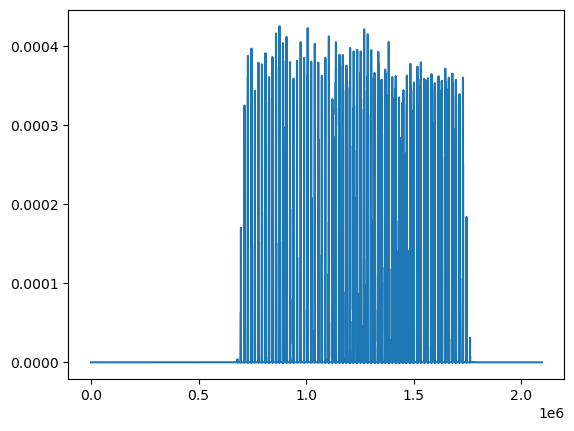

In [44]:

print(np.sum(f) * (2/(f.shape[0]))**3*np.pi/6)
plt.plot(f.flatten())

np.linalg.norm(f-f[0,0,0])

[[ 0.92238944+0.30072445j -0.92238944+0.30072445j  0.        -0.j
   0.        +0.j        ]
 [-0.07659139-0.05240315j  0.07659139-0.05240315j -0.10943332-0.16132634j
  -0.10943332+0.16132634j]
 [-0.00278784+0.00784129j  0.00278784+0.00784129j -0.01767416-0.00051016j
  -0.01767416+0.00051016j]
 [-0.01162646-0.0077068j   0.01162646-0.0077068j  -0.01590052-0.00684101j
  -0.01590052+0.00684101j]]
201.6556558147182


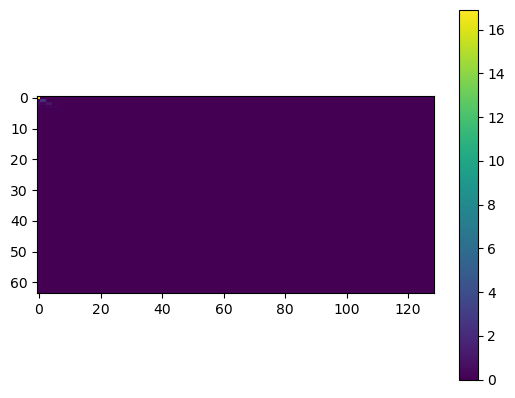

correlation R=0:  3.358108248555577
all correlation:  3.240056195661471
compute correlation:  65.12909078598022 

9.561198385952087e-06


In [45]:
importlib.reload(alignments)
d = 3            # dimensons
M = f.shape[0]   # grid size LxLxL
N = f.shape[0]
max_l = M//2

# z = np.linspace(-1, 1, N, endpoint=False)
zpos = np.linspace(0, 1, N, endpoint=True)

thetas = np.linspace(0, np.pi, N, endpoint=True)
phis = np.linspace(0, 2*np.pi, N, endpoint=False)

dVsphere = (zpos[1]-zpos[0])*(thetas[1]-thetas[0])*(phis[1]-phis[0]) 

# dVsphere = (z[1]-z[0])*(thetas[1]-thetas[0])*(phis[1]-phis[0]) 
# dVsphere = (z[1]-z[0])**3
# dVsphere = (2/(f.shape[0]))**3


sinthetas = np.sin(thetas)[np.newaxis, np.newaxis, :]
# r2 = z[:, np.newaxis, np.newaxis]**2
# sinthetas = np.ones(M)

f_t = transforms.Transform(f, d=3).inverse_cdf_transform()[0]
g_t = transforms.Transform(g, d=3).inverse_cdf_transform()[0]

fle = fle_3d.FLEBasis3D(M, M, 1e-6, max_l=max_l, mode="complex", force_real="True")

# import matplotlib.pyplot as plt
# plt.plot(f_t[0,:,0]*2*np.sqrt(np.pi))

t = time.time()
c = alignments.fast_rotational_correlation(f_t, g_t, fle)
print("compute correlation: ", time.time() - t, '\n')

print(dVsphere)

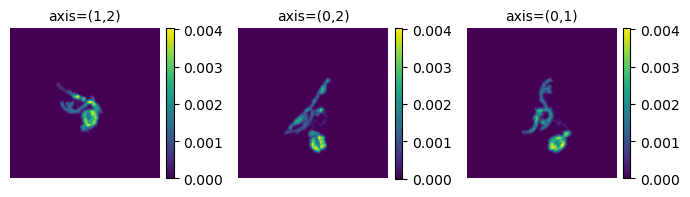

True

In [46]:
plots.orthogonal_2D_projection_plot(f)

np.allclose(f,g)

In [47]:
# f_t_norm = np.linalg.norm(f_t * sinthetas)
# g_t_norm = np.linalg.norm(g_t * sinthetas)


f_t_norm = np.sqrt(np.sum(f_t**2 * sinthetas))
g_t_norm = np.sqrt(np.sum(g_t**2 * sinthetas))



print(f_t_norm**2 * dVsphere/np.amax(c), g_t_norm**2 * dVsphere/np.amax(c))

1.0189849414024381 1.0189849414024381


In [48]:
# np.sum((f_t * g_t) * sinthetas**2) * dVsphere

np.sum(f_t * g_t * sinthetas) * dVsphere

3.421815580984773

In [49]:
np.amax(c), np.amin(c)

(3.35806295260389, 3.137089558687117)

In [50]:
2 * np.amax(c) 

6.71612590520778

In [21]:
f_t_norm**2 * dVsphere

3.904298454701957

In [22]:
# ( (f_t_norm**2 + g_t_norm**2) * dVsphere*4.288/6.681 - 2*np.amax(c) ) 

( (f_t_norm**2 + g_t_norm**2) * dVsphere - 2*np.amax(c) ) 

0.2041482228920266

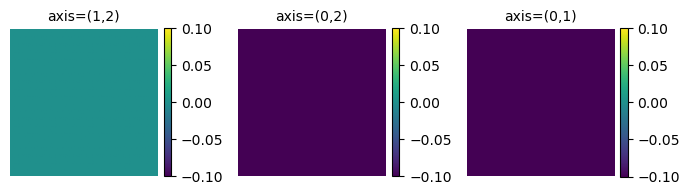

In [23]:
plots.orthogonal_2D_projection_plot(f - g)

In [24]:
### compute the distance from tensors, the expanded terms 
### and then compare to the correlation from FRC
### skip the 1/4pi average?

sinthetas = np.sin(thetas)[np.newaxis, np.newaxis, :]

### EV: if I use this they match, so not propogating the sin(theta) correctly?
# sinthetas = np.ones(M)



dS = (thetas[1]-thetas[0])*(phis[1]-phis[0])

d_total = np.sum((f_t*sinthetas - g_t*sinthetas)**2) 


### EV: probably should be the mean ?
# d_slices = np.mean((f_t*sinthetas - g_t*sinthetas)**2, axis=1)
# d_total = np.mean(d_slices)
# d_total = np.mean((f_t*sinthetas - g_t*sinthetas)**2)  # same thing


d_total * dS 

0.0

In [25]:
# np.linalg.norm(f_t * sinthetas)**2 * dS

In [26]:
# dS * ( np.linalg.norm(f_t * sinthetas)**2 + np.linalg.norm(g_t * sinthetas)**2 - 2*np.sum( (f_t * g_t)*sinthetas ) )


dS * ( np.linalg.norm(f_t * sinthetas)**2 + np.linalg.norm(g_t * sinthetas)**2 - 2*np.sum( (f_t * g_t)*sinthetas**2 ) ) 


7.124089612210751e-14

In [27]:
# np.mean(f_t * g_t) * dS

In [ ]:
np.allclose(np.linalg.norm(f_t * sinthetas)**2 , np.sum(f_t**2 * sinthetas**2))

In [ ]:
np.linalg.norm(f_t*sinthetas - g_t*sinthetas)**2 * dS

In [ ]:
sinthetas.shape


In [ ]:
a = np.random.randn(2,2)
b = np.random.randn(2)[np.newaxis,:]

In [ ]:
a

In [ ]:
b

In [ ]:
a*b

In [ ]:
importlib.reload(alignments)
lmax = fle.lmax+1


# sigma = 0.2
# p = np.array(np.meshgrid(*[z for _ in range(d)]))
# f = np.exp(-( np.sum(p**2, axis=0) ) / (2*sigma**2))
# g = f

# f2 = np.exp(-( z**2 ) / (2*sigma**2))
# g2 = f2

fhat = np.zeros((len(z), lmax, 2*lmax+1))
ghat = np.zeros((len(z), lmax, 2*lmax+1))
fhat[:,0,0] = f[M//2, M//2, :]*(2*np.sqrt(np.pi)) 
ghat[:,0,0] = g[M//2, M//2, :]*(2*np.sqrt(np.pi)) 
# fhat[:,0,0] = f2*(2*np.sqrt(np.pi)) 
# ghat[:,0,0] = g2*(2*np.sqrt(np.pi)) 
plt.figure()
plt.plot(fhat[:,0,0])
plt.plot(fhat[:,0,0]*(z>z[M//2-1]))
#these are now in order radius, l, m, where for fixed radius and l, the m index varies like
#m=0,-1,1,-2,2,-3,3, ...


Ilm = np.zeros((lmax,2*lmax+1,2*lmax+1),dtype=np.complex128)
# we need to remember to multiply by r^2, which cancels out the 1/abs(z) above...
for m1 in range(-lmax, lmax+1):
    m1ind = 2*np.abs(m1) - (m1 < 0)
    for m2 in range(-lmax, lmax+1):
        m2ind = 2*np.abs(m2) - (m2 < 0)
        #wfhat, ghat have a different ordering. m1ind and m2ind fix this
        for i in range(fhat.shape[0]):
            #should this actually only be for positive z? also need to divide by delta z...
            #we can use better quadrature here to get increased accuracy
            # if z[i] > 0:
            Ilm[:,m1+lmax,m2+lmax] += fhat[i,:,m1ind]*np.conj(ghat[i,:,m2ind])*(z[1]-z[0])*z[i]**2/2
print(np.sum(Ilm.flatten()))
# tmp2 = np.sum(Ilm[:,0,0])
tmp2 = np.sum(Ilm.flatten())

# tmp = 0
# for i in range(fhat.shape[0]):
#     #should this actually only be for positive z? also need to divide by delta z...
#     #we can use better quadrature here to get increased accuracy
#     # if z[i] > 0:
#     tmp += (fhat[i,0,0]**2)*(z[1]-z[0])*z[i]**2/2
  
# import scipy.integrate as integrate

# tmp2 = integrate.simpson(fhat[:,0,0]**2*z**2, x=z)/2 #/2 because you are doing the integral from -1 to so double-counting
# print('correlation R=0: ', tmp.real, tmp2)


In [ ]:
dz3 = (z[1]-z[0])**3
# dz3 = (2/(N))**3
f_t_norm = np.sqrt(np.sum(f**2)*dz3)
g_t_norm = np.sqrt(np.sum(g**2)*dz3)


print(f_t_norm**2, g_t_norm**2)
print(g_t_norm**2/tmp2)

In [ ]:
c = alignments.fast_rotational_correlation(f, g, fle)


In [ ]:
import torch
import torch_harmonics as th
n_phi, n_points, n_theta = f.shape

lmax = fle.lmax+1
f_t = transforms.Transform(f, d=3).cdf_transform()[0]

    
#Step 2: compute spherical harmonics coefficients
sht = th.RealSHT(n_theta, n_phi, lmax=lmax, grid="equiangular", csphase=True).to("cpu")

#torch_harmonics wants the order radius, theta, phi
f_swapped = np.transpose(f_t,(1,2,0))

plt.imshow(f_swapped[10,:,:])
plt.show()
plt.figure()
#Question: icf and icg are real-valued, right? Torch-harmonics only likes real inputs
#If not, we just have to call it twice, using the imaginary parts for the second call.
### EV: yes, real-valued. but we might want option for imaginary to compute Euclidean dist from the FT
fhat = fle.torch_reshape_order_t(sht(torch.DoubleTensor(np.real(f_swapped)).to("cpu")).cpu().numpy())
fhat = fhat[:,:,:(2*lmax+1)]


In [ ]:
plt.imshow(np.abs(fhat[10,:,:]))

In [53]:
# 3/4*(t-t^3/3 + 2/3) = y
# t - t^3/3 + 2/3 = 4*y/3
# t^3 + 4*y - 3*t - 2 = 0
# t^3 - 3*t + 4*y-2 = 0
y = 0.8
c = [1,0,-3,4*y-2]
np.roots(c)

array([-1.90521644,  1.47949789,  0.42571855])

In [52]:
np.roots([1,2])

array([-2.])